# Преобразование Хаара (3 ступени сжатия)

In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

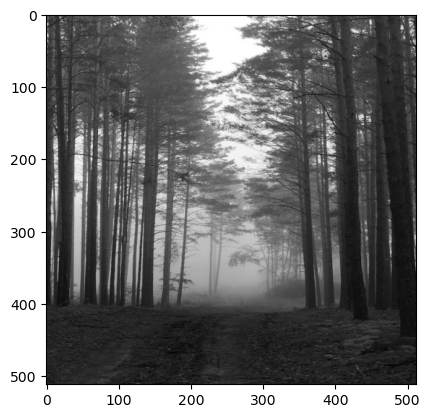

In [15]:
img = cv2.imread("image.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)
plt.imshow(img, cmap = 'gray')

In [16]:
def haar_step(data):
    height, width = data.shape

    even = data[:, 0::2]
    odd = data[:, 1::2]

    half_w = width // 2

    rows = np.zeros((height, width), dtype=np.float64)
    rows[:, :half_w] = (even + odd) / np.sqrt(2)
    rows[:, half_w:] = (even - odd) / np.sqrt(2)

    upper = rows[0::2, :]
    lower = rows[1::2, :]

    half_h = height // 2

    result = np.zeros((height, width), dtype=np.float64)
    result[:half_h, :] = (upper + lower) / np.sqrt(2)
    result[half_h:, :] = (upper - lower) / np.sqrt(2)

    return (
        result[:half_h, :half_w],
        result[:half_h, half_w:],
        result[half_h:, :half_w],
        result[half_h:, half_w:]
    )

In [17]:
levels = []
cur = img
for _ in range(3):
    bands = haar_step(cur)
    levels.append(bands)
    cur = bands[0]

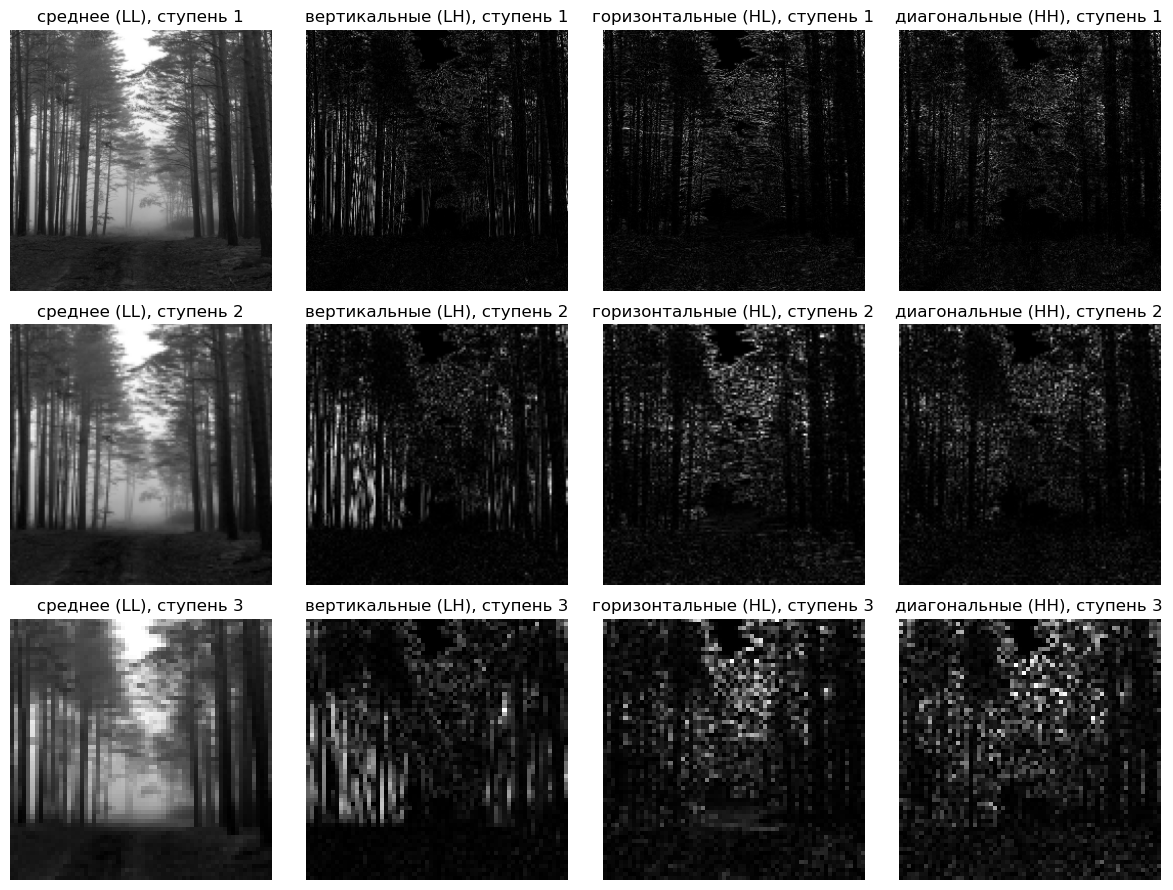

In [18]:
names = ["среднее (LL)", "вертикальные (LH)",
          "горизонтальные (HL)", "диагональные (HH)"]

fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for i, bands in enumerate(levels):
    for j, band in enumerate(bands):
        ax[i][j].imshow(np.abs(band), cmap="gray")
        ax[i][j].set_title(f"{names[j]}, ступень {i + 1}")
        ax[i][j].axis("off")

plt.tight_layout()
plt.show()